# 1. 环境配置

In [1]:
import torch
torch.__version__

'2.12.0+cu126'

In [2]:
import torch_geometric
torch_geometric.__version__

'2.8.1'

# 2. 基本介绍

pyG中, 一张图由`torch_geometric.data.Data`来表示:

1. `data.x`: 节点的特征 

Node feature matrix with shape `[num_nodes, num_node_features]`

1. `data.edge_index`: 存储边, 格式为 (起点, 终点) 

Graph connectivity in COO format with shape `[2, num_edges]` and type `torch.long`

3. `data.edge_attr`: 边的特征 

Edge feature matrix with shape `[num_edges, num_edge_features]`

4. `data.y`: 目标, 可以是每个节点单独的, 也可以是整个图的 

Target to train against (may have arbitrary shape), e.g., node-level targets of shape `[num_nodes, *]` or graph-level targets of shape `[1, *]`

5. `data.pos`: 节点位置 

Node position matrix with shape `[num_nodes, num_dimensions]`


下面构建一个如下的图:

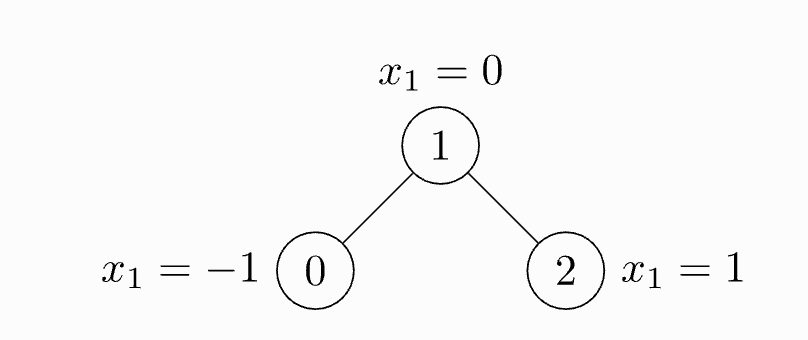

In [3]:
import torch
from torch_geometric.data import Data

x = torch.tensor([[-1], [0], [1]], dtype=torch.float32) # 下标为index, 内容为节点的值
edge_index = torch.tensor([
    [0, 1, 1, 2], 
    [1, 0, 2, 1]], dtype=torch.long) # 竖着读, (起点index, 终点index), 注意是torch.long
data = Data(x=x, edge_index=edge_index)
data

Data(x=[3, 1], edge_index=[2, 4])

In [4]:
# 或者edge还有另一种更符合直觉的写法
edge_index_new = torch.tensor([[0, 1], [1, 0], [1, 2], [2, 1]], dtype=torch.long)
data = Data(x=x, edge_index=edge_index_new.t().contiguous())
data

Data(x=[3, 1], edge_index=[2, 4])

In [5]:
# 查看edge_index中的值是否都在范围内
data.validate(raise_on_error=True)

True

In [6]:
print("data.keys(): \n", data.keys())
print("\ndata['x']: \n", data['x'])
print("\ndata['edge_index']: \n", data['edge_index'])

data.keys(): 
 ['x', 'edge_index']

data['x']: 
 tensor([[-1.],
        [ 0.],
        [ 1.]])

data['edge_index']: 
 tensor([[0, 1, 1, 2],
        [1, 0, 2, 1]])


In [7]:
data.num_edges, data.num_nodes, data.num_edge_features, data.num_node_features

(4, 3, 0, 1)

In [8]:
data.has_isolated_nodes(), data.has_self_loops(), data.is_directed()

(False, False, False)

# 3. 下载预设数据集

In [9]:
from torch_geometric.datasets import TUDataset

dataset = TUDataset(root='/tmp/ENZYMES', name='ENZYMES')

In [10]:
# 600张图
dataset, len(dataset)

(ENZYMES(600), 600)

In [11]:
print("classes: ", dataset.num_classes)
print("node features: ", dataset.num_node_features, "  labels: ", dataset.num_node_labels, "  attrs: ", dataset.num_node_attributes)
print("edge features: ", dataset.num_edge_features, "  labels: ", dataset.num_edge_labels, "  attrs: ", dataset.num_edge_attributes)

classes:  6
node features:  3   labels:  3   attrs:  18
edge features:  0   labels:  0   attrs:  0


In [12]:
data = dataset[0]
data, data.is_directed()
# 无向图, 168/2 = 84条边, 37个节点, 每个节点有 3 个feature, 该图对应一个target

(Data(edge_index=[2, 168], x=[37, 3], y=[1]), False)

In [13]:
data.x[:5], data.y

(tensor([[1., 0., 0.],
         [1., 0., 0.],
         [1., 0., 0.],
         [1., 0., 0.],
         [1., 0., 0.]]),
 tensor([5]))

# 4. 如何使用mini-batch、dataloader:

In [14]:
from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.utils import scatter


dataset = TUDataset(root='/tmp/ENZYMES', name='ENZYMES', use_node_attr=True)
loader = DataLoader(dataset, 32, True)

print(len(loader))

for data in loader:
    print("batch: ", data)
    print("batch graph number: ", data.num_graphs)
    # 把 src 张量里的元素，按照 index 分组，同一组做 sum /mean/max /min
    x = scatter(src= data.x, index= data.batch, dim=0, reduce='mean')
    print("x.size: ", x.size())
    break
# x.shape: [1149, 21], 这1149个 21维 向量 属于32张图, scatter将其按图序号进行聚合, 因此最终得到 [32, 21]的shape

19
batch:  DataBatch(edge_index=[2, 4462], x=[1125, 21], y=[32], batch=[1125], ptr=[33])
batch graph number:  32
x.size:  torch.Size([32, 21])


In [15]:
batch_0 = next(iter(loader))
batch_0
# batch属性: batch[i] = k -> 第i个节点属于图k
# ptr属性: ptr[k] = i -> 第k张图的起始节点的索引为i

DataBatch(edge_index=[2, 3846], x=[971, 21], y=[32], batch=[971], ptr=[33])

In [16]:
batch_0.batch[:50]

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1])

In [17]:
batch_0.y[:20]

tensor([5, 0, 2, 4, 2, 0, 4, 1, 5, 1, 1, 5, 0, 2, 4, 2, 0, 2, 1, 1])

In [18]:
batch_0.ptr

tensor([  0,  22,  51,  90, 132, 164, 178, 207, 251, 289, 329, 341, 361, 401,
        425, 449, 497, 541, 569, 594, 636, 668, 680, 710, 734, 775, 798, 833,
        848, 898, 939, 953, 971])

# 5. 如何做Transform

transforms类似torchvision

In [19]:
import torch_geometric.transforms as T
from torch_geometric.datasets import GeometricShapes

dataset = GeometricShapes(root='/tmp/Geo', pre_transform=T.KNNGraph(k=6))

Processing...
Done!


In [21]:
# 该数据集是点云, 只有点, 没有边, 因此需要transform进行变换
# 使用的是pre_transform, 数据集加载到内存之前，先预处理再保存到硬盘
# KNNGraph(k=6) 使用K近邻, 每个点连接距离最近的 6 个点(有向边)
dataset[0]

Data(pos=[32, 3], face=[3, 30], y=[1], edge_index=[2, 192])

In [22]:
# 也可以进行 data augmentation
dataset = GeometricShapes(root='/tmp/Geo', 
                          pre_transform=T.KNNGraph(k=6),
                          transform= T.RandomJitter(0.01))
dataset[0]

Data(pos=[32, 3], face=[3, 30], y=[1], edge_index=[2, 192])

# 6. 实操创建一个GCN

In [24]:
# 准备数据集
from torch_geometric.datasets import Planetoid
dataset = Planetoid(root='/tmp/Cora', name='Cora')

In [ ]:
len(dataset) # 一张图

1

In [28]:
import torch
from torch import nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class GCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(dataset.num_node_features, 16)
        self.conv2 = GCNConv(16, dataset.num_classes)
    
    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        
        x = F.dropout(F.relu(self.conv1(x, edge_index)))
        return F.log_softmax(self.conv2(x, edge_index), dim=1)

In [32]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = GCN().to(device)
data = dataset[0].to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

model.train()
for epoch in range(200):
    optimizer.zero_grad()
    out = model(data)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    if epoch % 20 == 0:
        print("train_loss: ", loss.item())

train_loss:  1.9427521228790283
train_loss:  0.2605893909931183
train_loss:  0.05135059356689453
train_loss:  0.03965483233332634
train_loss:  0.05849730595946312
train_loss:  0.03884114697575569
train_loss:  0.04425138607621193
train_loss:  0.0422893650829792
train_loss:  0.02799595519900322
train_loss:  0.03925413638353348


In [34]:
model.eval()
with torch.inference_mode():
    pred = model(data).argmax(dim=1)
    correct = (pred[data.test_mask] == data.y[data.test_mask]).sum()
    acc = int(correct) / int(data.test_mask.sum())
    print(f'Accuracy: {acc:.4f}')

Accuracy: 0.7690
